# 03. Внешняя проверка на независимых данных

До сих пор все проверки делались внутри TCGA: те же протоколы, тот же конвейер обработки, похожие больницы. Настоящая проверка — данные, которые собрали **другие люди, в других клиниках, другим методом**. Модель не переобучается: берём ту же модель, обученную на TCGA, и просто применяем её.

**Два независимых набора:**

| Набор | Что это | Чем отличается от TCGA |
|---|---|---|
| **CPTAC-3** | первичные опухоли из проспективного проекта CPTAC (другие пациенты и клиники) | другой конвейер (GDC STAR), единицы log2(TPM + 1) |
| **MET500** | биопсии метастазов, Мичиганский университет (Robinson et al., *Nature* 2017) | метастазы, другая лаборатория, log2(TPM + 0.001), часть образцов после exome-capture |

Расчёт делает `src/external.py`, ноутбук читает его результаты.

In [1]:
import json
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

R = "../results"
ext = json.load(open(f"{R}/external.json"))

## Проблема шкалы и как её решить

Числа в разных наборах данных несравнимы: в TCGA выражение гена может быть «10», а в MET500 тот же уровень записан как «3» или «−2». Модель обучена на шкале TCGA, поэтому на «сырых» внешних данных она бессильна.

Решение — **квантильная нормализация к TCGA, по одному образцу**: внутри каждого внешнего образца гены сортируются по уровню, и каждому присваивается значение того же ранга из «типичного» образца TCGA. Порядок генов внутри образца (что выражено сильнее, что слабее) сохраняется, а шкала становится как в TCGA. Важно, что каждый образец нормализуется **сам по себе**: мы не подсматриваем в остальную внешнюю выборку и не используем её метки.

Гены, которых нет во внешних данных (10–13% генов модели — переименованы или иначе аннотированы), заполняются медианой TCGA.

In [2]:
rows = []
for name, key in (("CPTAC-3", "cptac3"), ("MET500", "met500")):
    r = ext[key]
    for label in ("raw", "quantile_normalised"):
        rows.append({"набор": name, "данные": "сырые" if label == "raw" else "нормализованные",
                     "образцов": r[label]["n"], "точность": round(r[label]["accuracy"], 3),
                     "топ-3": round(r[label]["top3_accuracy"], 3),
                     "генов модели найдено": f"{r['model_genes_present']} из {r['model_genes']}"})
pd.DataFrame(rows)

,набор,данные,образцов,точность,топ-3,генов модели найдено
0,CPTAC-3,сырые,1266,0.134,0.572,4475 из 5000
1,CPTAC-3,нормализованные,1266,0.908,0.993,4475 из 5000
2,MET500,сырые,437,0.064,0.240,4358 из 5000
3,MET500,нормализованные,437,0.657,0.810,4358 из 5000


**Что видно:** без нормализации точность почти случайная (13% и 6%), с нормализацией — 91% и 66%. Это, пожалуй, главный практический урок: модель, обученная на одной платформе, без согласования шкалы не работает на другой, даже если биология та же.

## CPTAC-3: независимые первичные опухоли

1 266 опухолей восьми типов, один образец на пациента.

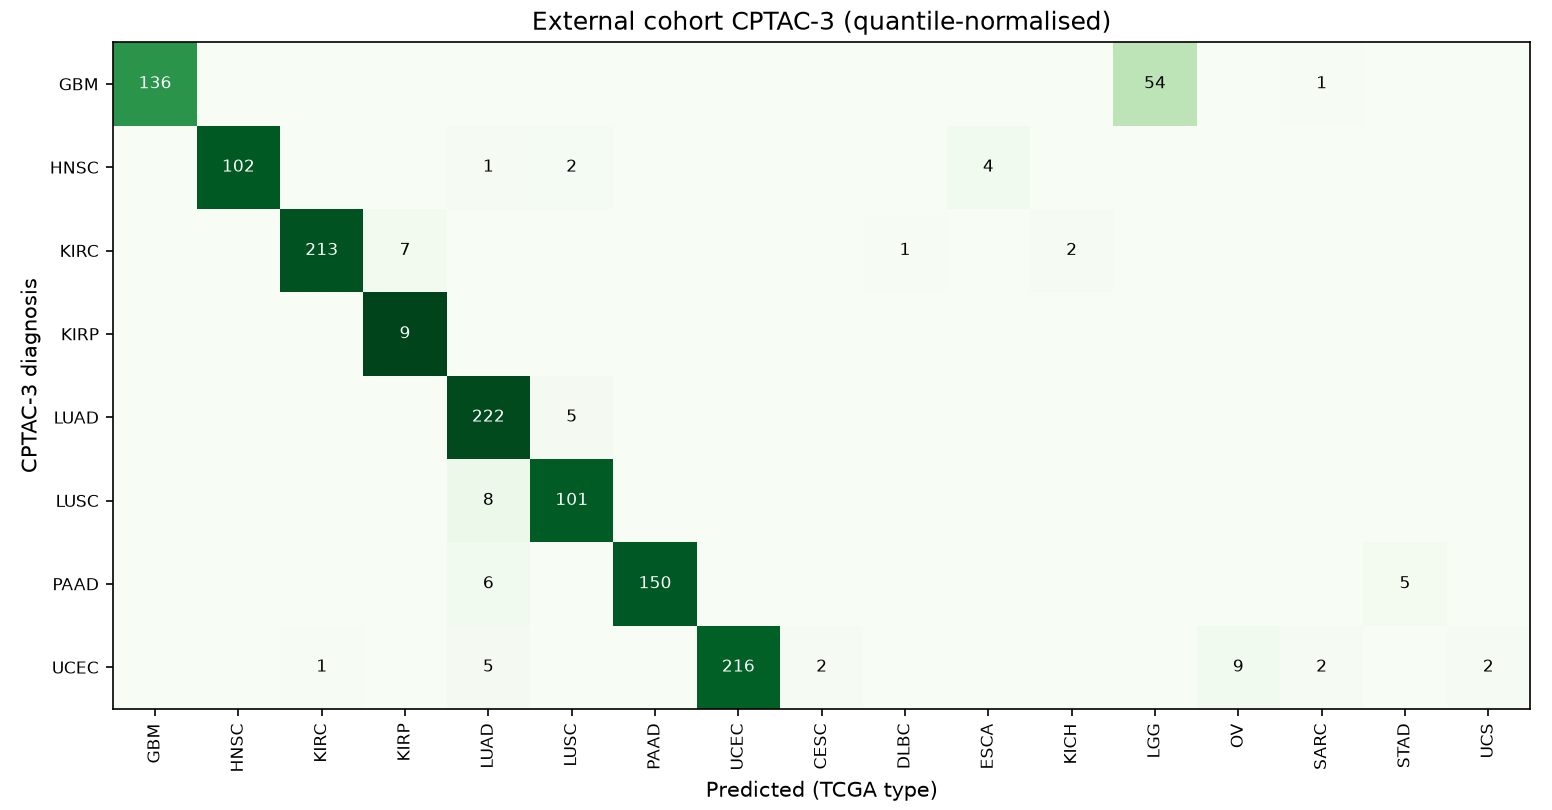

,cancer_type,correct,n,точность
0,GBM,136,191,0.712
1,HNSC,102,109,0.936
2,KIRC,213,223,0.955
3,KIRP,9,9,1.000
4,LUAD,222,227,0.978
5,LUSC,101,109,0.927
6,PAAD,150,161,0.932
7,UCEC,216,237,0.911


In [3]:
display(Image(f"{R}/figures/external_cptac3.png", width=900))
pt = pd.DataFrame(ext["cptac3"]["per_type"]).assign(точность=lambda d: (d.correct / d.n).round(3))
pt

In [4]:
ext["cptac3"]["top_errors"]

{'GBM -> LGG': 54,
 'UCEC -> OV': 9,
 'LUSC -> LUAD': 8,
 'KIRC -> KIRP': 7,
 'PAAD -> LUAD': 6,
 'LUAD -> LUSC': 5,
 'PAAD -> STAD': 5,
 'UCEC -> LUAD': 5,
 'HNSC -> ESCA': 4,
 'KIRC -> KICH': 2}

**Что видно:**

- **Точность 90.8%, правильный ответ в топ-3 у 99.3%** — на данных из других клиник и другого конвейера. Для сравнения, на тесте TCGA было 97%.
- Все типы, кроме глиобластомы, узнаются на 91–100%. Ошибки в основном между близкими классами: плоскоклеточный ↔ аденокарцинома лёгкого, светлоклеточный ↔ папиллярный рак почки, эндометрий → яичник.
- **Главная ошибка: глиобластома → глиома низкой степени (54 из 191).** Это одна ткань (глия), различие в степени злокачественности. В TCGA модель путала их редко, но в CPTAC, видимо, другие критерии отбора образцов и другая доля опухолевых клеток. Без этой пары точность была бы около 95%.

## MET500: метастазы из другой лаборатории

437 пациентов (по одному образцу), только те группы, у которых есть аналог в TCGA. Если в MET500 указан только орган (лёгкое, кишка, почка), ответ засчитывается для любого типа TCGA этого органа.

In [5]:
pc = pd.DataFrame(ext["met500"]["per_cohort"]).assign(точность=lambda d: (d.correct / d.n).round(2))
pc.sort_values("n", ascending=False)

,cohort,correct,n,точность
2,BRCA,69,92,0.75
13,PRAD,69,91,0.76
14,SARC,43,58,0.74
3,CHOL,11,26,0.42
10,LUNG,19,24,0.79
8,HNSC,10,24,0.42
1,BLCA,8,16,0.50
12,PAAD,5,14,0.36
11,OV,9,13,0.69
15,SKCM,9,13,0.69


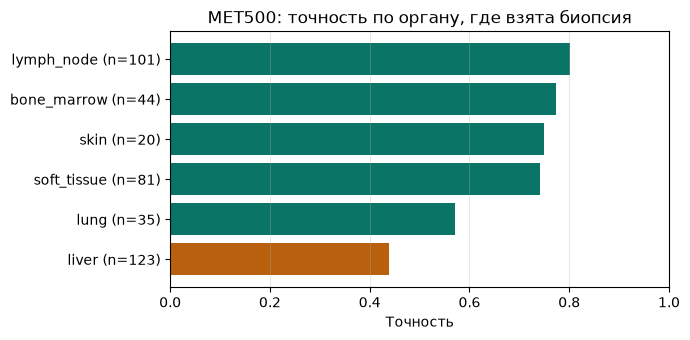

{'errors': 150, 'named_the_biopsy_organ': 55}
{'BRCA -> LIHC': 16, 'HNSC -> LUSC': 8, 'CHOL -> LIHC': 7, 'PRAD -> LIHC': 5, 'HNSC -> CESC': 4, 'CHOL -> PAAD': 4, 'PRAD -> BRCA': 4, 'ESCA -> LIHC': 4, 'SARC -> MESO': 3, 'SARC -> LUSC': 3, 'STAD -> SARC': 3, 'PRAD -> DLBC': 3}


In [6]:
site = pd.DataFrame(ext["met500"]["by_biopsy_site"]).sort_values("accuracy")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(site.biopsy_tissue + " (n=" + site.n.astype(str) + ")", site.accuracy,
        color=["#b8600e" if t == "liver" else "#0a7466" for t in site.biopsy_tissue])
ax.set_xlim(0, 1)
ax.set_xlabel("Точность")
ax.set_title("MET500: точность по органу, где взята биопсия")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
print(ext["met500"]["predicted_as_biopsy_organ"])
print(ext["met500"]["top_errors"])

**Что видно:**

- **Точность 66%, топ-3 81%.** Заметно ниже, чем на CPTAC и на метастазах TCGA (92%). Но и задача сложнее: другая лаборатория, часть образцов после exome-capture (на них 60% против 67% у poly-A), и метастазы из самых разных органов.
- **Метастазы в печени — худший случай (44%).** Самая частая ошибка: рак груди в печени назван раком печени (16 раз). Ещё по холангиокарциноме, простате, пищеводу то же самое. Из 150 ошибок **55 — это название органа, где взята биопсия**. Модель читает окружающую нормальную ткань, а не опухоль.
- Это то, что мы предсказали в ноутбуке 02 по SHAP (сурфактанты в LUSC) и увидели на метастазах TCGA (рак груди → печень, мезотелиома). Теперь это подтверждено на независимых данных и в большом масштабе.
- Метастазы в лимфоузлах и мягких тканях узнаются лучше (74–80%): там окружающая ткань не похожа ни на один тип рака из обучения.

## Итоги

| Набор | Точность | Топ-3 | Вывод |
|---|---|---|---|
| Тест TCGA (первичные) | 0.970 | 0.998 | исходная оценка |
| **CPTAC-3** (первичные, другие клиники) | **0.908** | **0.993** | модель переносится на новые данные |
| Метастазы TCGA | 0.924 | 0.980 | в основном меланома |
| **MET500** (метастазы, другая лаборатория) | **0.657** | **0.810** | главная слабость: примесь ткани органа |

**Что можно улучшить дальше:**
1. Добавить в обучение нормальные ткани (например, GTEx) как отдельный класс «фон», чтобы модель научилась не путать печень-орган с раком печени.
2. Оценивать долю опухоли в образце и вычитать вклад нормальной ткани (деконволюция).
3. Обучать модель сразу на рангах внутри образца, чтобы она не зависела от шкалы платформы.

**Ограничения.** Метки CPTAC и MET500 сопоставлены с типами TCGA вручную; некоторые группы MET500 маленькие (3–13 пациентов); 10–13% генов модели отсутствуют во внешних данных из-за разной аннотации генов.